In [5]:
%pip install lightkurve astropy numpy pandas matplotlib scipy torch torchvision torchaudio scikit-learn tqdm -q

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightkurve as lk

from astropy.io import fits

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [7]:
print("Lightkurve Version:", lk.__version__)

Lightkurve Version: 2.6.0


In [8]:
# Search TESS observations of one star

TARGET = "Pi Mensae"

search_result = lk.search_lightcurve(
    TARGET,
    mission="TESS",
    author="SPOC"
)

search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,261136679,0.0
1,TESS Sector 04,2018,SPOC,120,261136679,0.0
2,TESS Sector 08,2019,SPOC,120,261136679,0.0
3,TESS Sector 11,2019,SPOC,120,261136679,0.0
4,TESS Sector 12,2019,SPOC,120,261136679,0.0
5,TESS Sector 13,2019,SPOC,120,261136679,0.0
6,TESS Sector 27,2020,SPOC,20,261136679,0.0
7,TESS Sector 28,2020,SPOC,20,261136679,0.0
8,TESS Sector 31,2020,SPOC,20,261136679,0.0


In [9]:
lc = search_result[0].download()

lc

time,flux,flux_err,timecorr,cadenceno,centroid_col,centroid_row,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,d,,pix,pix,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,float32,int32,float64,float64,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
1325.2969604950604,1.4641956e+06,1.3036719e+02,1.2319778e-03,70445,1630.67624,260.67540,1.4354926e+06,1.2776145e+02,3.9114688e+03,1.5351995e+01,1.4641956e+06,1.3036719e+02,0,———,———,———,———,1630.67624,8.4099076e-05,260.67540,1.3968609e-04,9.0913408e-02,-7.2966635e-02
1325.2983493645327,1.4643365e+06,1.3035809e+02,1.2319590e-03,70446,1630.64880,260.63392,1.4357199e+06,1.2775254e+02,3.8596919e+03,1.5269516e+01,1.4643365e+06,1.3035809e+02,0,———,———,———,———,1630.64880,8.4054744e-05,260.63392,1.3961994e-04,6.2022530e-02,-1.0871942e-01
1325.299738234005,1.4643485e+06,1.3035931e+02,1.2319401e-03,70447,1630.64806,260.62840,1.4356588e+06,1.2775373e+02,3.8692920e+03,1.5291610e+01,1.4643485e+06,1.3035931e+02,0,———,———,———,———,1630.64806,8.4062471e-05,260.62840,1.3959571e-04,6.1673984e-02,-1.1394957e-01
1325.301127103477,1.4643674e+06,1.3035008e+02,1.2319213e-03,70448,1630.64752,260.61434,1.4356190e+06,1.2774468e+02,3.8398132e+03,1.5262703e+01,1.4643674e+06,1.3035008e+02,0,———,———,———,———,1630.64752,8.4045743e-05,260.61434,1.3958366e-04,6.0909923e-02,-1.2573890e-01
1325.3025159730657,1.4642560e+06,1.3034836e+02,1.2319025e-03,70449,1630.64057,260.61412,1.4355810e+06,1.2774299e+02,3.8384204e+03,1.5262712e+01,1.4642560e+06,1.3034836e+02,0,———,———,———,———,1630.64057,8.4043444e-05,260.61412,1.3952980e-04,5.3837594e-02,-1.2532526e-01
1325.303904842538,1.4644681e+06,1.3035623e+02,1.2318837e-03,70450,1630.63971,260.61326,1.4358005e+06,1.2775071e+02,3.8069717e+03,1.5240330e+01,1.4644681e+06,1.3035623e+02,0,———,———,———,———,1630.63971,8.4056861e-05,260.61326,1.3949080e-04,5.2977830e-02,-1.2562653e-01
1325.3052937121265,1.4643586e+06,1.3035381e+02,1.2318649e-03,70451,1630.64385,260.60708,1.4356219e+06,1.2774834e+02,3.8431169e+03,1.5283619e+01,1.4643586e+06,1.3035381e+02,0,———,———,———,———,1630.64385,8.4062158e-05,260.60708,1.3951714e-04,5.7222184e-02,-1.3051888e-01
1325.3066825815986,1.4643564e+06,1.3035527e+02,1.2318461e-03,70452,1630.64220,260.61215,1.4356771e+06,1.2774977e+02,3.8419392e+03,1.5270525e+01,1.4643564e+06,1.3035527e+02,0,———,———,———,———,1630.64220,8.4041087e-05,260.61215,1.3955019e-04,5.5443291e-02,-1.2712292e-01


In [10]:
print(type(lc))


<class 'lightkurve.lightcurve.TessLightCurve'>


In [11]:
print(lc.columns)

<TableColumns names=('time','flux','flux_err','timecorr','cadenceno','centroid_col','centroid_row','sap_flux','sap_flux_err','sap_bkg','sap_bkg_err','pdcsap_flux','pdcsap_flux_err','quality','psf_centr1','psf_centr1_err','psf_centr2','psf_centr2_err','mom_centr1','mom_centr1_err','mom_centr2','mom_centr2_err','pos_corr1','pos_corr2')>


In [12]:
lc

time,flux,flux_err,timecorr,cadenceno,centroid_col,centroid_row,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,d,,pix,pix,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,float32,int32,float64,float64,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
1325.2969604950604,1.4641956e+06,1.3036719e+02,1.2319778e-03,70445,1630.67624,260.67540,1.4354926e+06,1.2776145e+02,3.9114688e+03,1.5351995e+01,1.4641956e+06,1.3036719e+02,0,———,———,———,———,1630.67624,8.4099076e-05,260.67540,1.3968609e-04,9.0913408e-02,-7.2966635e-02
1325.2983493645327,1.4643365e+06,1.3035809e+02,1.2319590e-03,70446,1630.64880,260.63392,1.4357199e+06,1.2775254e+02,3.8596919e+03,1.5269516e+01,1.4643365e+06,1.3035809e+02,0,———,———,———,———,1630.64880,8.4054744e-05,260.63392,1.3961994e-04,6.2022530e-02,-1.0871942e-01
1325.299738234005,1.4643485e+06,1.3035931e+02,1.2319401e-03,70447,1630.64806,260.62840,1.4356588e+06,1.2775373e+02,3.8692920e+03,1.5291610e+01,1.4643485e+06,1.3035931e+02,0,———,———,———,———,1630.64806,8.4062471e-05,260.62840,1.3959571e-04,6.1673984e-02,-1.1394957e-01
1325.301127103477,1.4643674e+06,1.3035008e+02,1.2319213e-03,70448,1630.64752,260.61434,1.4356190e+06,1.2774468e+02,3.8398132e+03,1.5262703e+01,1.4643674e+06,1.3035008e+02,0,———,———,———,———,1630.64752,8.4045743e-05,260.61434,1.3958366e-04,6.0909923e-02,-1.2573890e-01
1325.3025159730657,1.4642560e+06,1.3034836e+02,1.2319025e-03,70449,1630.64057,260.61412,1.4355810e+06,1.2774299e+02,3.8384204e+03,1.5262712e+01,1.4642560e+06,1.3034836e+02,0,———,———,———,———,1630.64057,8.4043444e-05,260.61412,1.3952980e-04,5.3837594e-02,-1.2532526e-01
1325.303904842538,1.4644681e+06,1.3035623e+02,1.2318837e-03,70450,1630.63971,260.61326,1.4358005e+06,1.2775071e+02,3.8069717e+03,1.5240330e+01,1.4644681e+06,1.3035623e+02,0,———,———,———,———,1630.63971,8.4056861e-05,260.61326,1.3949080e-04,5.2977830e-02,-1.2562653e-01
1325.3052937121265,1.4643586e+06,1.3035381e+02,1.2318649e-03,70451,1630.64385,260.60708,1.4356219e+06,1.2774834e+02,3.8431169e+03,1.5283619e+01,1.4643586e+06,1.3035381e+02,0,———,———,———,———,1630.64385,8.4062158e-05,260.60708,1.3951714e-04,5.7222184e-02,-1.3051888e-01
1325.3066825815986,1.4643564e+06,1.3035527e+02,1.2318461e-03,70452,1630.64220,260.61215,1.4356771e+06,1.2774977e+02,3.8419392e+03,1.5270525e+01,1.4643564e+06,1.3035527e+02,0,———,———,———,———,1630.64220,8.4041087e-05,260.61215,1.3955019e-04,5.5443291e-02,-1.2712292e-01


In [13]:
# Extract only the columns we need

time = lc.time.value

sap_flux = lc.sap_flux.value

sap_flux_err = lc.sap_flux_err.value

quality = lc.quality

print("Number of observations:", len(time))

print("First Time :", time[0])

print("First SAP Flux :", sap_flux[0])

print("First Error :", sap_flux_err[0])

print("First Quality :", quality[0])

Number of observations: 18264
First Time : 1325.2969604950604
First SAP Flux : 1435492.6
First Error : 127.76145
First Quality : 0


In [14]:
df = pd.DataFrame({
    "time": np.asarray(time, dtype=np.float64),
    "sap_flux": np.asarray(sap_flux, dtype=np.float64),
    "sap_flux_err": np.asarray(sap_flux_err, dtype=np.float64),
    "quality": np.asarray(quality, dtype=np.int32)
})

df.head()

,time,sap_flux,sap_flux_err,quality
0,1325.296960,1435492.625,127.761452,0
1,1325.298349,1435719.875,127.752541,0
2,1325.299738,1435658.750,127.753731,0
3,1325.301127,1435619.000,127.744682,0
4,1325.302516,1435581.000,127.742989,0


In [15]:
print(df.isnull().sum())

time            0
sap_flux        0
sap_flux_err    0
quality         0
dtype: int64


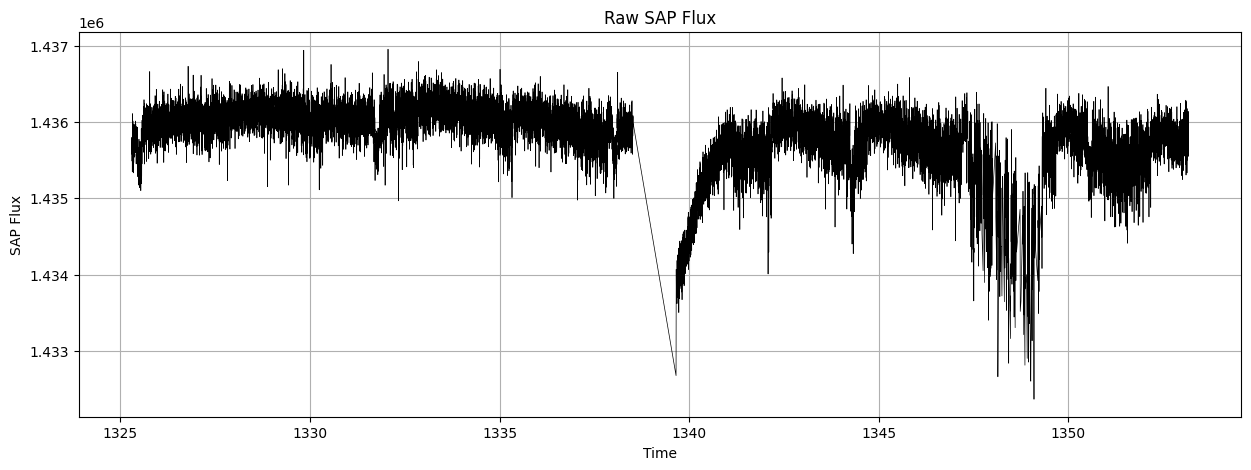

In [16]:
plt.figure(figsize=(15,5))

plt.plot(
    df["time"],
    df["sap_flux"],
    color="black",
    linewidth=0.5
)

plt.title("Raw SAP Flux")

plt.xlabel("Time")

plt.ylabel("SAP Flux")

plt.grid(True)

plt.show()

In [17]:
print(df["quality"].value_counts())

quality
0    18264
Name: count, dtype: int64


In [18]:
# Convert quality to native integer before counting
quality_native = np.array(df["quality"], dtype=np.int32)

unique, counts = np.unique(quality_native, return_counts=True)

for q, c in zip(unique, counts):
    print(f"Quality Flag {q}: {c} points")

Quality Flag 0: 18264 points


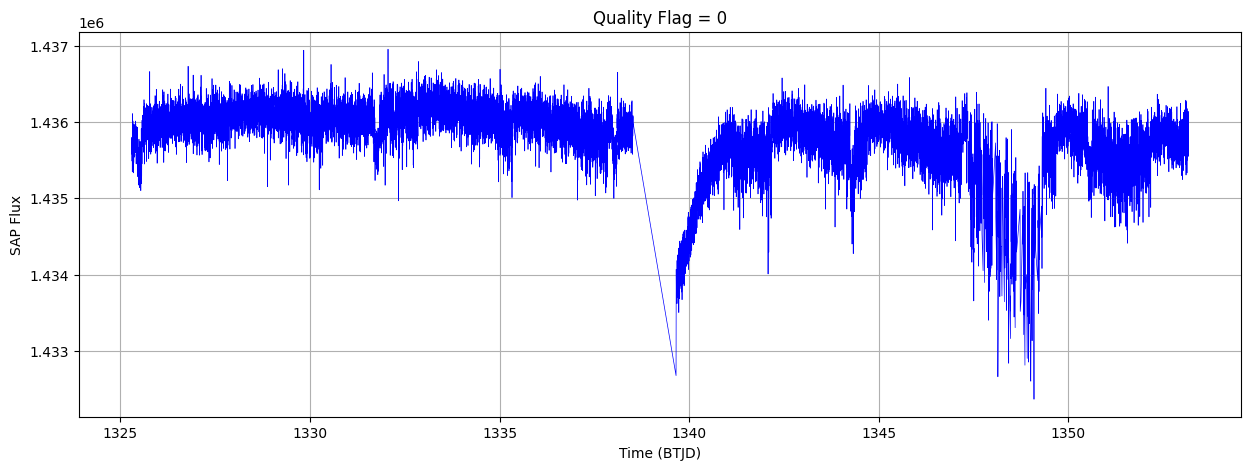

In [19]:
good_df = df[df["quality"] == 0].copy()

plt.figure(figsize=(15,5))

plt.plot(
    good_df["time"],
    good_df["sap_flux"],
    color="blue",
    linewidth=0.5
)

plt.title("Quality Flag = 0")

plt.xlabel("Time (BTJD)")
plt.ylabel("SAP Flux")

plt.grid(True)

plt.show()

In [20]:
print("Original points :", len(df))
print("Filtered points :", len(good_df))


Original points : 18264
Filtered points : 18264


In [21]:
# Normalize the flux

median_flux = np.median(good_df["sap_flux"])

good_df["normalized_flux"] = good_df["sap_flux"] / median_flux

print(good_df.head())

          time     sap_flux  sap_flux_err  quality  normalized_flux
0  1325.296960  1435492.625    127.761452        0         0.999715
1  1325.298349  1435719.875    127.752541        0         0.999873
2  1325.299738  1435658.750    127.753731        0         0.999830
3  1325.301127  1435619.000    127.744682        0         0.999803
4  1325.302516  1435581.000    127.742989        0         0.999776


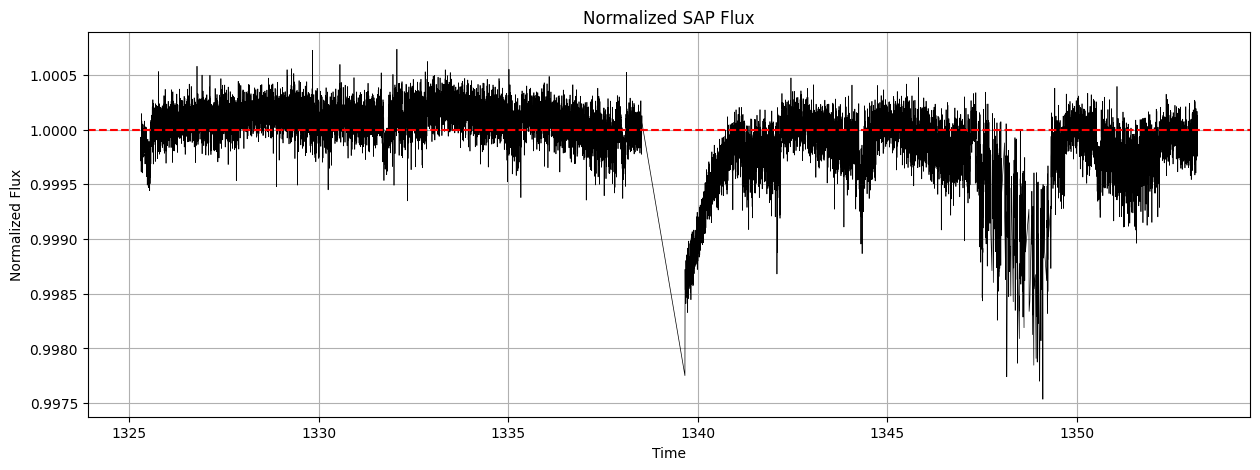

In [22]:
plt.figure(figsize=(15,5))

plt.plot(
    good_df["time"],
    good_df["normalized_flux"],
    color="black",
    linewidth=0.5
)

plt.axhline(1.0,color="red",linestyle="--")

plt.title("Normalized SAP Flux")

plt.xlabel("Time")

plt.ylabel("Normalized Flux")

plt.grid(True)

plt.show()

In [23]:
from scipy.signal import savgol_filter

# Copy the dataframe
work_df = good_df.copy()

# Smooth long-term trend
trend = savgol_filter(
    work_df["normalized_flux"],
    window_length=501,   # Must be odd
    polyorder=2
)

# Remove trend
work_df["detrended_flux"] = work_df["normalized_flux"] / trend

print(work_df.head())

          time     sap_flux  sap_flux_err  quality  normalized_flux  \
0  1325.296960  1435492.625    127.761452        0         0.999715   
1  1325.298349  1435719.875    127.752541        0         0.999873   
2  1325.299738  1435658.750    127.753731        0         0.999830   
3  1325.301127  1435619.000    127.744682        0         0.999803   
4  1325.302516  1435581.000    127.742989        0         0.999776   

   detrended_flux  
0        0.999917  
1        1.000075  
2        1.000032  
3        1.000003  
4        0.999976  


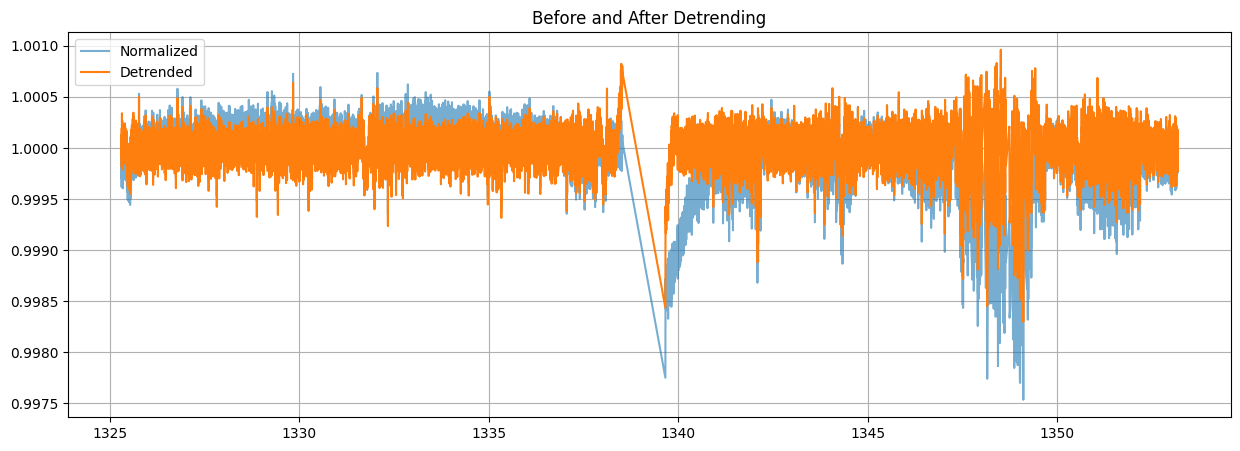

In [24]:
plt.figure(figsize=(15,5))

plt.plot(
    work_df["time"],
    work_df["normalized_flux"],
    label="Normalized",
    alpha=0.6
)

plt.plot(
    work_df["time"],
    work_df["detrended_flux"],
    label="Detrended"
)

plt.legend()
plt.grid(True)
plt.title("Before and After Detrending")
plt.show()

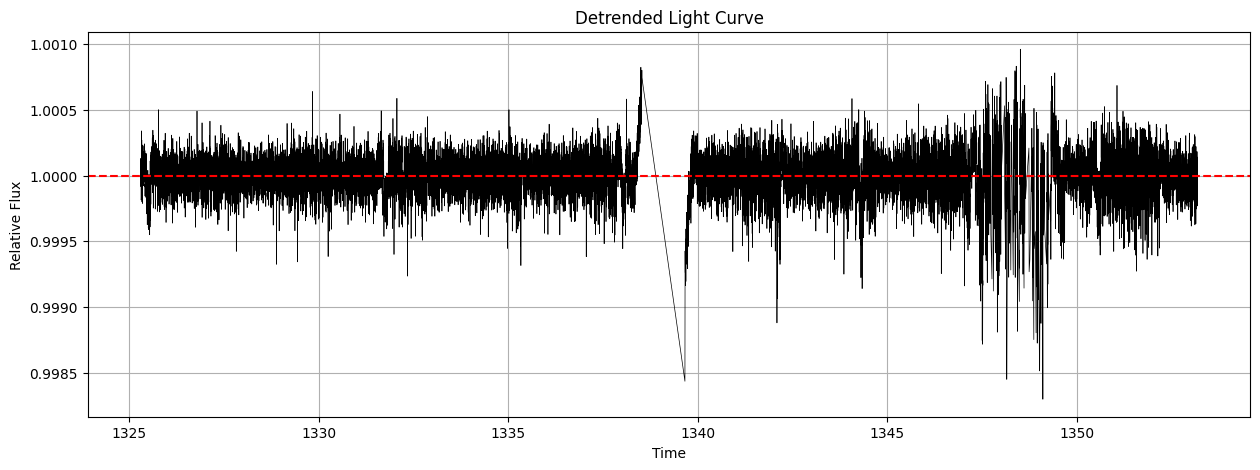

In [25]:
plt.figure(figsize=(15,5))

plt.plot(
    work_df["time"],
    work_df["detrended_flux"],
    color="black",
    linewidth=0.5
)

plt.axhline(1, color="red", linestyle="--")

plt.title("Detrended Light Curve")

plt.xlabel("Time")

plt.ylabel("Relative Flux")

plt.grid(True)

plt.show()

In [26]:
from astropy.timeseries import BoxLeastSquares

In [27]:
time = work_df["time"].values

flux = work_df["detrended_flux"].values

In [28]:
bls = BoxLeastSquares(time, flux)

In [29]:
import numpy as np

periods = np.linspace(0.5, 30, 10000)

durations = np.linspace(0.05, 0.30, 10)

bls_power = bls.power(periods, durations)

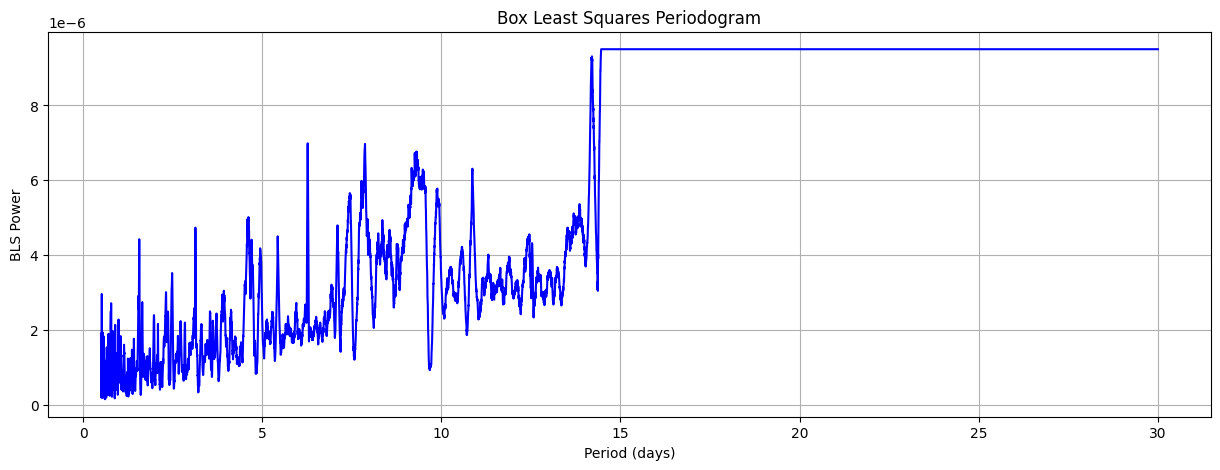

In [30]:
plt.figure(figsize=(15,5))

plt.plot(
    bls_power.period,
    bls_power.power,
    color="blue"
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")

plt.title("Box Least Squares Periodogram")

plt.grid(True)

plt.show()

In [31]:
best = np.argmax(bls_power.power)

print("Best Period:", bls_power.period[best], "days")

print("Transit Duration:", bls_power.duration[best], "days")

print("Transit Depth:", bls_power.depth[best])

Best Period: 14.457845784578458 days
Transit Duration: 0.105 days
Transit Depth: 0.0005247693929870636


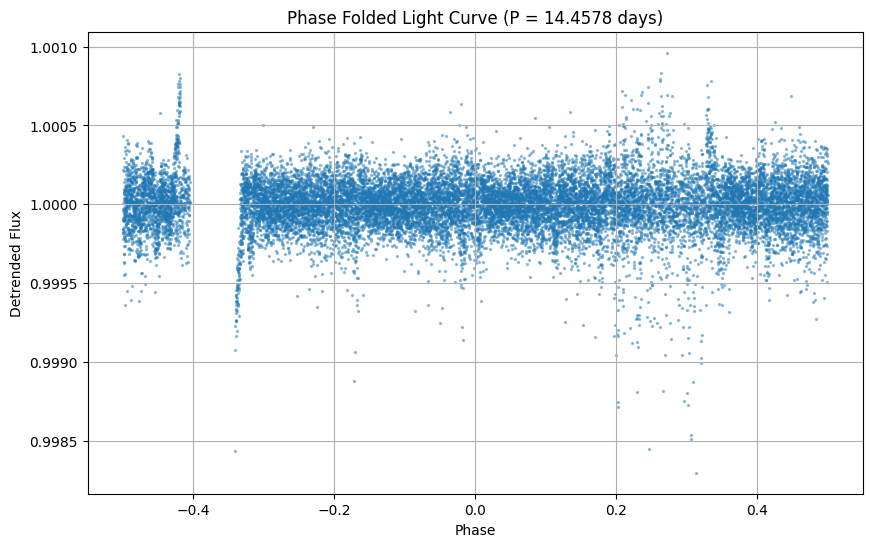

In [32]:
best_period = bls_power.period[best]

folded = work_df.copy()

phase = ((folded["time"] / best_period) % 1)

phase[phase > 0.5] -= 1

folded["phase"] = phase

plt.figure(figsize=(10,6))

plt.scatter(
    folded["phase"],
    folded["detrended_flux"],
    s=2,
    alpha=0.4
)

plt.xlabel("Phase")

plt.ylabel("Detrended Flux")

plt.title(f"Phase Folded Light Curve (P = {best_period:.4f} days)")

plt.grid(True)

plt.show()

In [33]:
from astropy.timeseries import LombScargle

In [34]:
frequency, power = LombScargle(
    time,
    flatten_flux
).autopower()

NameError: name 'flatten_flux' is not defined

In [ ]:
print("Does flatten_flux exist?", "flatten_flux" in globals())

Does flatten_flux exist? False


In [ ]:
from wotan import flatten

ModuleNotFoundError: No module named 'wotan'

In [ ]:
%pip install wotan

You should consider upgrading via the 'c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [35]:
from wotan import flatten

time = good_df["time"].values
flux = good_df["normalized_flux"].values

flatten_flux, trend = flatten(
    time,
    flux,
    method="biweight",
    window_length=0.5,
    return_trend=True
)

print("✅ Wotan successful!")
print(flatten_flux[:5])

✅ Wotan successful!
[0.9999081  1.00006499 1.00002185 0.99999395 0.99996818]


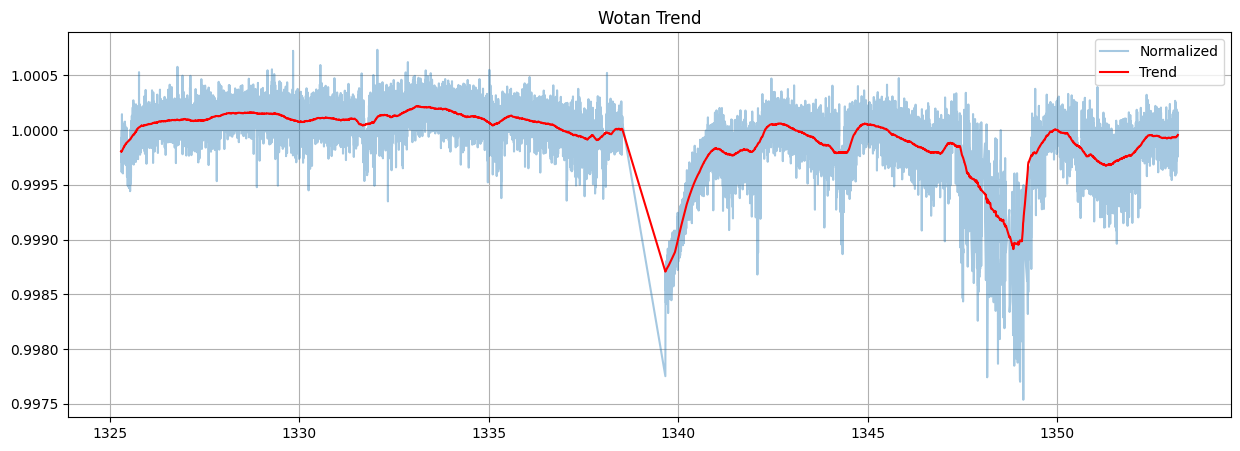

In [36]:
plt.figure(figsize=(15,5))

plt.plot(time, flux, alpha=0.4, label="Normalized")
plt.plot(time, trend, color="red", label="Trend")

plt.legend()
plt.grid(True)
plt.title("Wotan Trend")
plt.show()

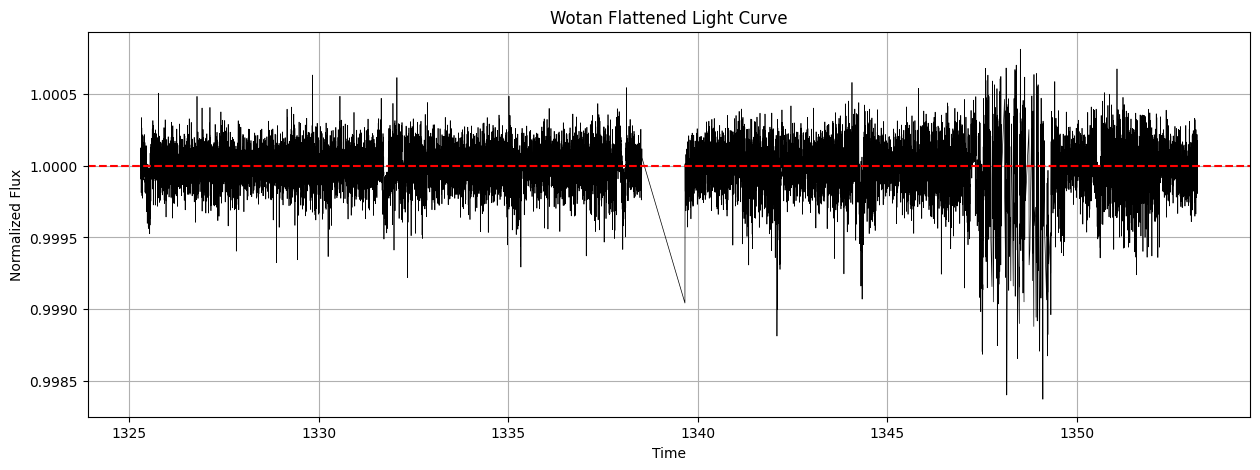

In [37]:
plt.figure(figsize=(15,5))

plt.plot(time, flatten_flux, "k", linewidth=0.5)

plt.axhline(1, color="red", linestyle="--")

plt.title("Wotan Flattened Light Curve")
plt.xlabel("Time")
plt.ylabel("Normalized Flux")

plt.grid(True)
plt.show()

In [38]:
from astropy.timeseries import BoxLeastSquares

bls = BoxLeastSquares(time, flatten_flux)

periods = np.linspace(0.5, 30, 10000)

durations = np.linspace(0.05, 0.30, 10)

bls_power = bls.power(periods, durations)

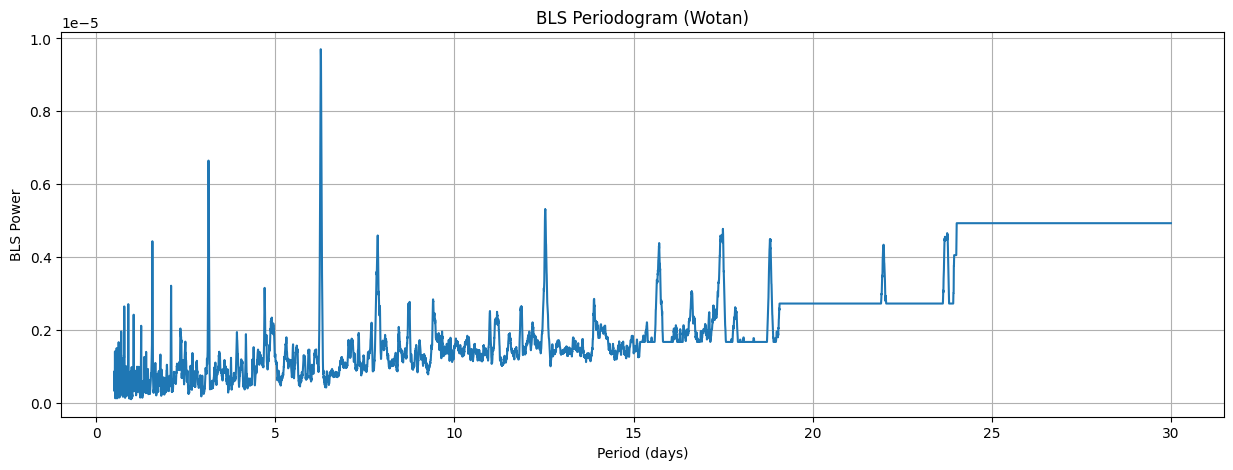

In [39]:
plt.figure(figsize=(15,5))

plt.plot(bls_power.period, bls_power.power)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")

plt.title("BLS Periodogram (Wotan)")

plt.grid(True)

plt.show()

In [40]:
best = np.argmax(bls_power.power)

best_period = bls_power.period[best]

print("Best Period :", best_period)
print("Duration :", bls_power.duration[best])
print("Depth :", bls_power.depth[best])

Best Period : 6.267826782678268
Duration : 0.105
Depth : 0.00022840287009832328


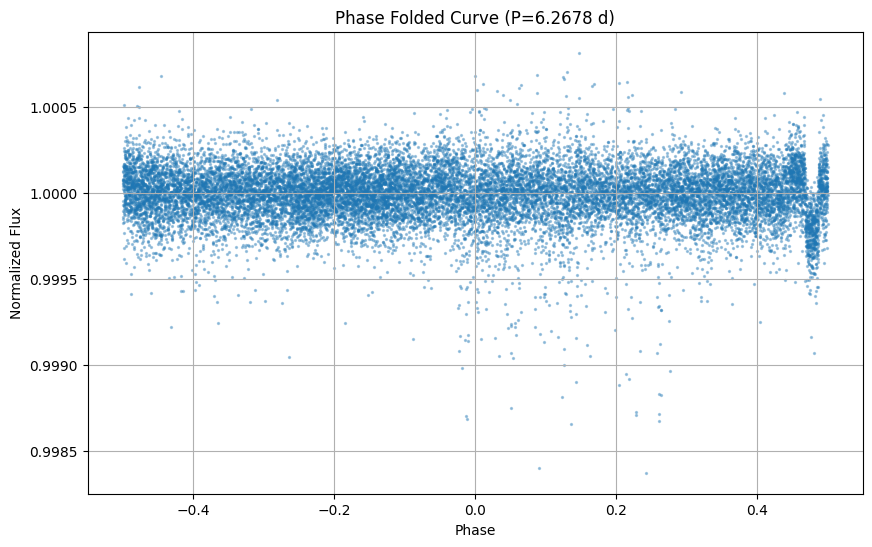

In [41]:
phase = (time % best_period) / best_period
phase[phase > 0.5] -= 1

plt.figure(figsize=(10,6))

plt.scatter(
    phase,
    flatten_flux,
    s=2,
    alpha=0.35
)

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title(f"Phase Folded Curve (P={best_period:.4f} d)")

plt.grid(True)

plt.show()

In [42]:
# Sort by phase
order = np.argsort(phase)

phase_sorted = phase[order]
flux_sorted = flatten_flux[order]

# Bin the data
bins = np.linspace(-0.5, 0.5, 201)

digitized = np.digitize(phase_sorted, bins)

phase_bin = []
flux_bin = []

for i in range(1, len(bins)):
    mask = digitized == i
    if np.sum(mask) > 5:
        phase_bin.append(np.mean(phase_sorted[mask]))
        flux_bin.append(np.mean(flux_sorted[mask]))

phase_bin = np.array(phase_bin)
flux_bin = np.array(flux_bin)

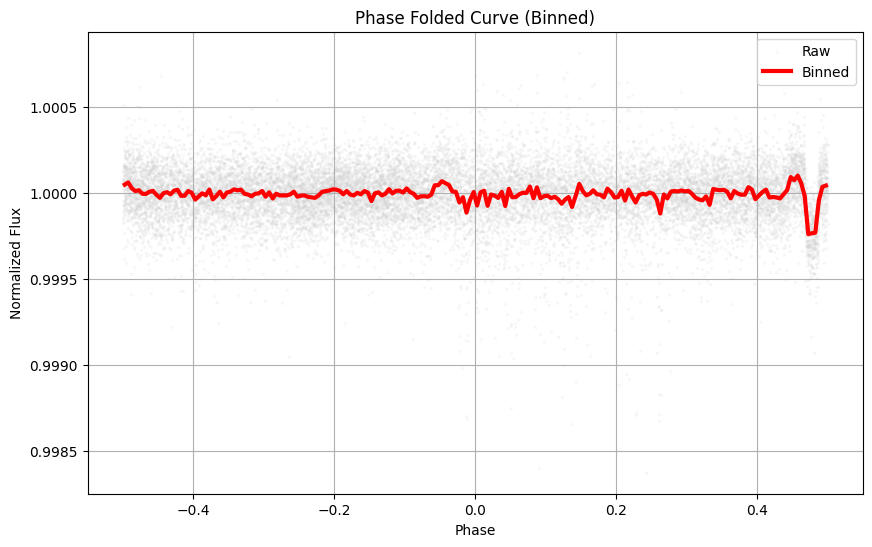

In [43]:
plt.figure(figsize=(10,6))

plt.scatter(
    phase,
    flatten_flux,
    s=2,
    alpha=0.12,
    color="lightgray",
    label="Raw"
)

plt.plot(
    phase_bin,
    flux_bin,
    color="red",
    linewidth=3,
    label="Binned"
)

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")

plt.title("Phase Folded Curve (Binned)")

plt.legend()

plt.grid(True)

plt.show()

In [44]:
# Find the top 10 BLS peaks

power = bls_power.power
period = bls_power.period
duration = bls_power.duration
depth = bls_power.depth

# Sort by power
indices = np.argsort(power)[::-1]

print("Top 10 BLS Candidates\n")

for i in range(10):
    idx = indices[i]
    print(f"{i+1}. "
          f"Period = {period[idx]:.4f} d | "
          f"Power = {power[idx]:.6e} | "
          f"Duration = {duration[idx]:.4f} d | "
          f"Depth = {depth[idx]:.6f}")

Top 10 BLS Candidates

1. Period = 6.2678 d | Power = 9.703224e-06 | Duration = 0.1050 d | Depth = 0.000228
2. Period = 6.2708 d | Power = 9.686691e-06 | Duration = 0.1050 d | Depth = 0.000229
3. Period = 6.2649 d | Power = 9.531733e-06 | Duration = 0.1050 d | Depth = 0.000226
4. Period = 6.2737 d | Power = 9.513665e-06 | Duration = 0.1050 d | Depth = 0.000226
5. Period = 6.2619 d | Power = 8.987417e-06 | Duration = 0.1050 d | Depth = 0.000220
6. Period = 6.2767 d | Power = 8.870477e-06 | Duration = 0.1050 d | Depth = 0.000219
7. Period = 6.2796 d | Power = 8.167141e-06 | Duration = 0.1050 d | Depth = 0.000209
8. Period = 6.2590 d | Power = 8.087209e-06 | Duration = 0.1050 d | Depth = 0.000209
9. Period = 6.2826 d | Power = 7.455416e-06 | Duration = 0.1050 d | Depth = 0.000199
10. Period = 6.2560 d | Power = 7.331817e-06 | Duration = 0.1050 d | Depth = 0.000199


In [45]:
from scipy.signal import find_peaks

# Find local maxima
peaks, properties = find_peaks(
    bls_power.power,
    distance=80,          # minimum separation
    prominence=5e-7       # ignore tiny peaks
)

print("Number of independent peaks:", len(peaks))

Number of independent peaks: 41


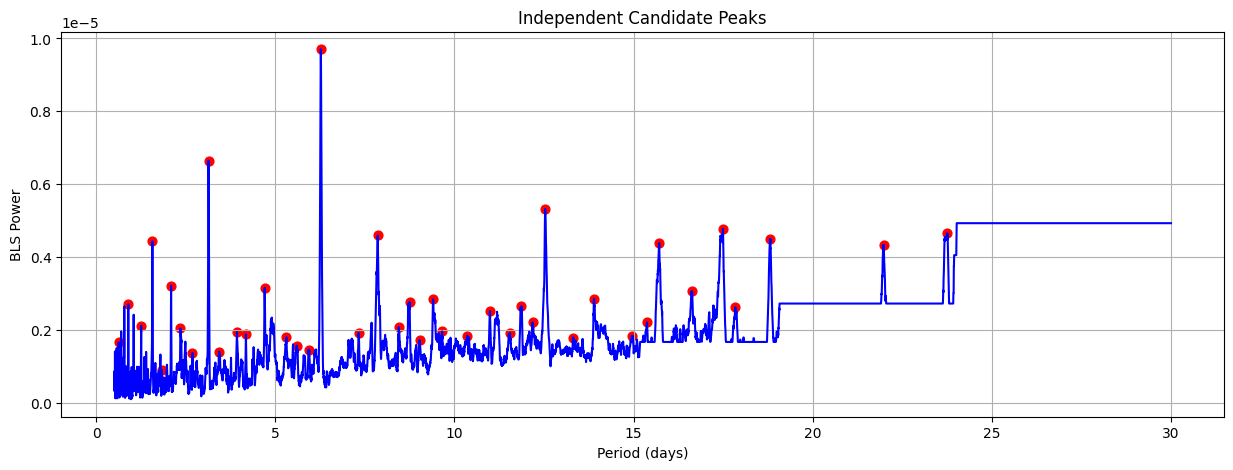

In [46]:
plt.figure(figsize=(15,5))

plt.plot(
    bls_power.period,
    bls_power.power,
    color="blue"
)

plt.scatter(
    bls_power.period[peaks],
    bls_power.power[peaks],
    color="red",
    s=40
)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")

plt.title("Independent Candidate Peaks")

plt.grid(True)

plt.show()

In [47]:
candidate_periods = bls_power.period[peaks]
candidate_power = bls_power.power[peaks]
candidate_duration = bls_power.duration[peaks]
candidate_depth = bls_power.depth[peaks]

order = np.argsort(candidate_power)[::-1]

print("Independent Candidates\n")

for i in order[:10]:

    print(
        f"Period = {candidate_periods[i]:.4f} d | "
        f"Power = {candidate_power[i]:.6e} | "
        f"Depth = {candidate_depth[i]:.6f}"
    )

Independent Candidates

Period = 6.2678 d | Power = 9.703224e-06 | Depth = 0.000228
Period = 3.1346 d | Power = 6.650618e-06 | Depth = 0.000142
Period = 12.5313 d | Power = 5.317524e-06 | Depth = 0.000216
Period = 17.4937 d | Power = 4.780090e-06 | Depth = 0.000316
Period = 23.7542 d | Power = 4.663047e-06 | Depth = 0.000310
Period = 7.8580 d | Power = 4.598662e-06 | Depth = 0.000254
Period = 18.8213 d | Power = 4.492859e-06 | Depth = 0.000247
Period = 1.5680 d | Power = 4.440366e-06 | Depth = 0.000086
Period = 15.7147 d | Power = 4.391024e-06 | Depth = 0.000261
Period = 21.9781 d | Power = 4.345068e-06 | Depth = 0.000260


In [48]:
filtered = []

tolerance = 0.02      # 2%

for p in candidate_periods[order]:

    harmonic = False

    for fp in filtered:

        ratio = p / fp

        if abs(ratio-0.5)<tolerance:
            harmonic=True

        elif abs(ratio-2)<tolerance:
            harmonic=True

    if not harmonic:
        filtered.append(p)

print("Final Candidate Periods\n")

for p in filtered:
    print(f"{p:.4f} days")

Final Candidate Periods

6.2678 days
17.4937 days
23.7542 days
7.8580 days
18.8213 days
1.5680 days
21.9781 days
2.0902 days
4.7012 days
16.6263 days
13.8973 days
0.8953 days
17.8359 days
15.3724 days
1.2553 days
7.3270 days
10.3599 days
14.9535 days
13.3102 days
5.5981 days
5.9462 days
3.4355 days
2.6862 days
1.8276 days


In [49]:
import sys

sys.path.append("../src")

from dataset_builder import DatasetBuilder

In [51]:
builder = DatasetBuilder(
    folded.phase.to_numpy(),
    folded_flux
)

NameError: name 'folded_flux' is not defined

In [52]:
print(type(folded))

<class 'pandas.core.frame.DataFrame'>


In [53]:
print(folded.head())

          time     sap_flux  sap_flux_err  quality  normalized_flux  \
0  1325.296960  1435492.625    127.761452        0         0.999715   
1  1325.298349  1435719.875    127.752541        0         0.999873   
2  1325.299738  1435658.750    127.753731        0         0.999830   
3  1325.301127  1435619.000    127.744682        0         0.999803   
4  1325.302516  1435581.000    127.742989        0         0.999776   

   detrended_flux     phase  
0        0.999917 -0.333719  
1        1.000075 -0.333623  
2        1.000032 -0.333526  
3        1.000003 -0.333430  
4        0.999976 -0.333334  


In [54]:
print(globals().keys())

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__vsc_ipynb_file__', '_i', '_ii', '_iii', '_i1', 'warnings', 'np', 'pd', 'plt', 'lk', 'fits', '_i2', 'TARGET', 'search_result', '_2', '_i3', '_i4', '_i5', '_exit_code', '_i6', '_i7', '_i8', '_8', '_i9', 'lc', '_9', '_i10', '_i11', '_i12', '_12', '_i13', 'time', 'sap_flux', 'sap_flux_err', 'quality', '_i14', 'df', '_14', '_i15', '_i16', '_i17', '_i18', 'quality_native', 'unique', 'counts', 'q', 'c', '_i19', 'good_df', '_i20', '_i21', 'median_flux', '_i22', '_i23', 'savgol_filter', 'work_df', 'trend', '_i24', '_i25', '_i26', 'BoxLeastSquares', '_i27', 'flux', '_i28', 'bls', '_i29', 'periods', 'durations', 'bls_power', '_i30', '_i31', 'best', '_i32', 'best_period', 'folded', 'phase', '_i33', 'LombScargle', '_i34', '_i35', 'flatten', 'flatten_flux', '_i36', '_i37', '_i38', '_i39', '_i40', '_i41'

In [55]:
builder = DatasetBuilder(
    folded["phase"].to_numpy(),
    folded["detrended_flux"].to_numpy()
)

In [56]:
import importlib
import dataset_builder

importlib.reload(dataset_builder)

from dataset_builder import DatasetBuilder

In [57]:
builder = DatasetBuilder(
    folded["phase"].to_numpy(),
    folded["detrended_flux"].to_numpy()
)

sample = builder.build_sample()

print(sample.keys())

dict_keys(['local_x', 'local_y', 'global_x', 'global_y', 'secondary_x', 'secondary_y'])


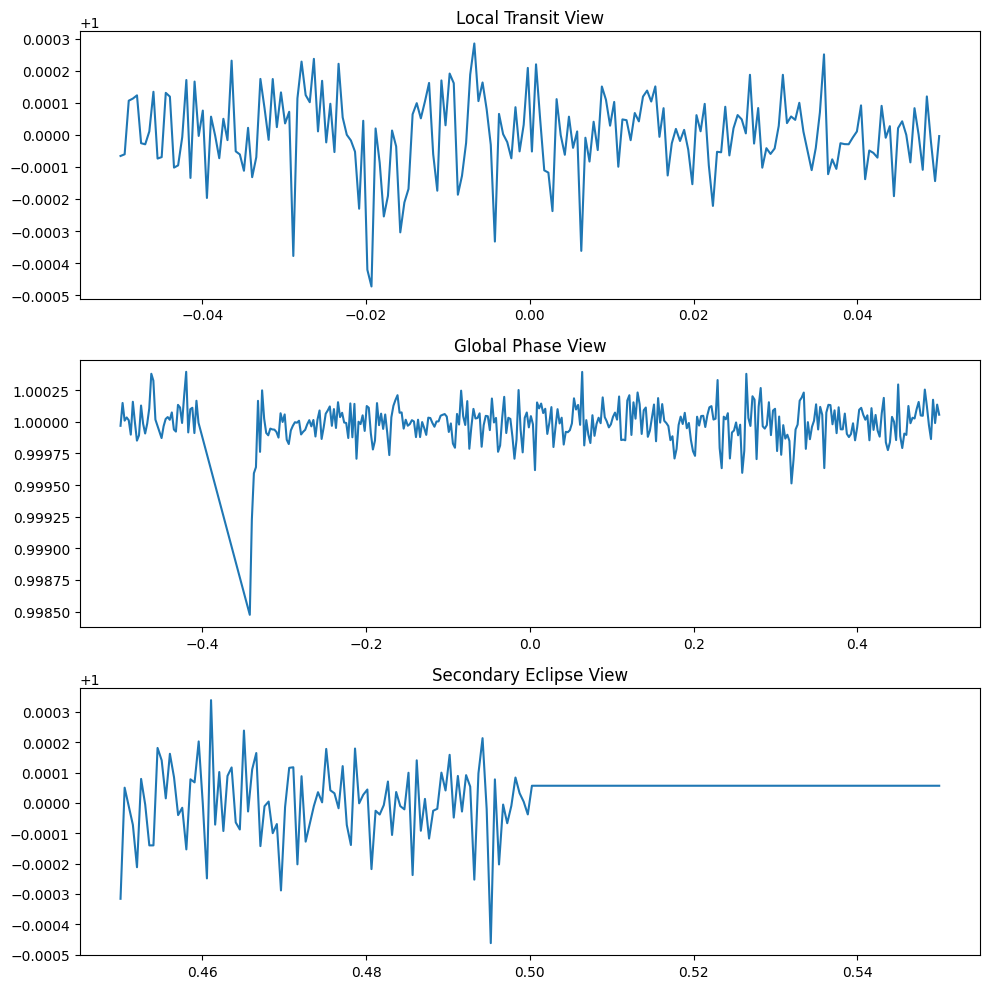

In [58]:
fig, ax = plt.subplots(3,1, figsize=(10,10))

ax[0].plot(sample["local_x"], sample["local_y"])
ax[0].set_title("Local Transit View")

ax[1].plot(sample["global_x"], sample["global_y"])
ax[1].set_title("Global Phase View")

ax[2].plot(sample["secondary_x"], sample["secondary_y"])
ax[2].set_title("Secondary Eclipse View")

plt.tight_layout()
plt.show()

In [59]:
import feature_extractor

import importlib

importlib.reload(feature_extractor)

from feature_extractor import FeatureExtractor

In [60]:
extractor = FeatureExtractor(sample)

features = extractor.extract()

features

{'depth': np.float64(0.0004726961976556643),
 'duration': np.int64(36),
 'snr': np.float64(3.804644449064653),
 'symmetry': np.float64(0.00014803055716602453),
 'rms': np.float64(0.0001242418848814831)}

In [61]:
import importlib
import candidate_ranker

importlib.reload(candidate_ranker)

from candidate_ranker import CandidateRanker

In [62]:
ranker = CandidateRanker(features)

score, explanation = ranker.score()

print("Planet Score:", score, "/100")

print()

for e in explanation:
    print("✓", e)

Planet Score: 80 /100

✓ Weak but detectable
✓ Symmetric transit
✓ Low stellar noise
✓ Physically plausible depth
✓ Reasonable duration
